In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50

# Load MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Convert grayscale -> RGB
x_train = tf.image.grayscale_to_rgb(
    tf.expand_dims(x_train, -1)
)
x_test = tf.image.grayscale_to_rgb(
    tf.expand_dims(x_test, -1)
)

# Resize 28x28 -> 32x32
x_train = tf.image.resize(x_train, (32, 32))
x_test = tf.image.resize(x_test, (32, 32))

# Normalize
x_train = x_train / 255.0
x_test = x_test / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


# **Transfer Learning**

In [ ]:
model1 = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(32, 32, 3)
)

# Freeze entire ResNet
model1.trainable = False

# Build model
model = models.Sequential([
    model1,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

# Compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

# Test
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Test Accuracy:", test_acc)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 33s 27ms/step - accuracy: 0.7337 - loss: 0.8302 - val_accuracy: 0.8943 - val_loss: 0.3712
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8484 - loss: 0.4762 - val_accuracy: 0.9245 - val_loss: 0.2662
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8703 - loss: 0.4100 - val_accuracy: 0.9217 - val_loss: 0.2559
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8805 - loss: 0.3757 - val_accuracy: 0.9338 - val_loss: 0.2164
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8878 - loss: 0.3505 - val_accuracy: 0.9422 - val_loss: 0.1885
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8932 - loss: 0.3338 - val_accuracy: 0.9412 - val_loss: 0.1900
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8977 - loss: 0.3213 - val_accuracy: 0.9267 - val_loss: 0.2214
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8975 - loss: 0.3163 - val_ac

# **Fine Tuning**

In [ ]:
# Unfreeze ResNet layers
model1.trainable = True

# Freeze early layers
for layer in model1.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization frozen
for layer in model1.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Changed / added classification layers
model = tf.keras.Sequential([
    model1,

    tf.keras.layers.GlobalAveragePooling2D(),

    # Changed from 128 -> 256
    tf.keras.layers.Dense(256, activation='relu'),

    # New layer
    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(10, activation='softmax')
])

# Small learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Fine-tuning
history_fine = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 33ms/step - accuracy: 0.6618 - loss: 1.0408 - val_accuracy: 0.8812 - val_loss: 0.3746
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.8582 - loss: 0.4632 - val_accuracy: 0.8942 - val_loss: 0.3250
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.8906 - loss: 0.3588 - val_accuracy: 0.9385 - val_loss: 0.2080
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9015 - loss: 0.3203 - val_accuracy: 0.9325 - val_loss: 0.2139
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9116 - loss: 0.2878 - val_accuracy: 0.9448 - val_loss: 0.1765
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9198 - loss: 0.2620 - val_accuracy: 0.9488 - val_loss: 0.1562
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9246 - loss: 0.2476 - val_accuracy: 0.9367 - val_loss: 0.2069
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9305 - loss: 0.2294 - 

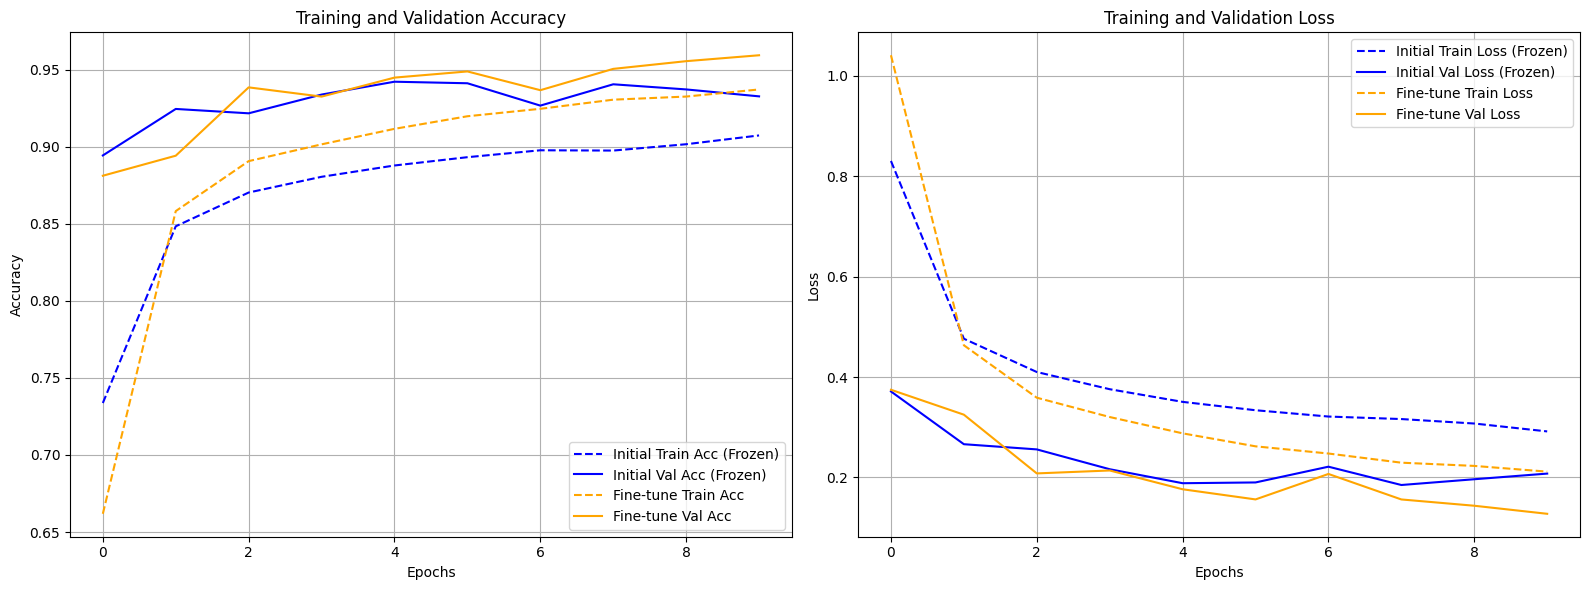

In [ ]:
import matplotlib.pyplot as plt

# Set up the plotting grid
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. Plot Accuracy Comparison
ax1.plot(history.history['accuracy'], label='Initial Train Acc (Frozen)', color='blue', linestyle='--')
ax1.plot(history.history['val_accuracy'], label='Initial Val Acc (Frozen)', color='blue')
ax1.plot(history_fine.history['accuracy'], label='Fine-tune Train Acc', color='orange', linestyle='--')
ax1.plot(history_fine.history['val_accuracy'], label='Fine-tune Val Acc', color='orange')
ax1.set_title('Training and Validation Accuracy')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# 2. Plot Loss Comparison
ax2.plot(history.history['loss'], label='Initial Train Loss (Frozen)', color='blue', linestyle='--')
ax2.plot(history.history['val_loss'], label='Initial Val Loss (Frozen)', color='blue')
ax2.plot(history_fine.history['loss'], label='Fine-tune Train Loss', color='orange', linestyle='--')
ax2.plot(history_fine.history['val_loss'], label='Fine-tune Val Loss', color='orange')
ax2.set_title('Training and Validation Loss')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


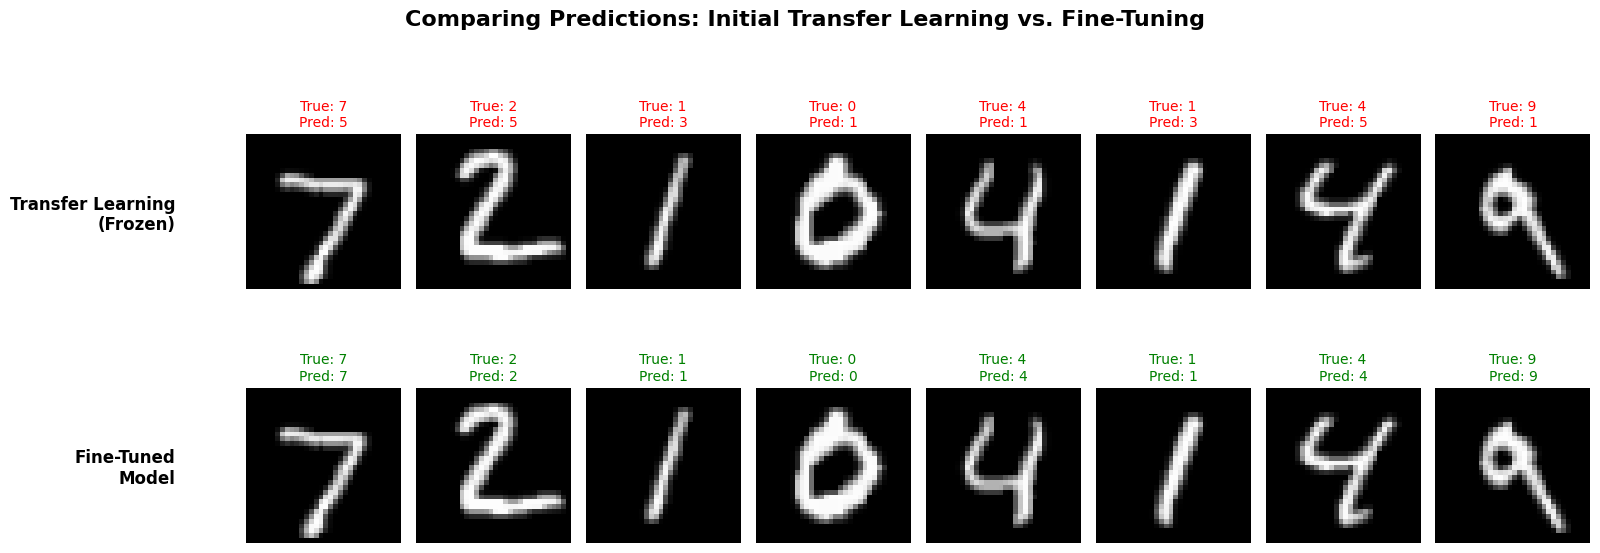

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model

# To get predictions from the initial transfer learning stage, we can create a model using the frozen ResNet base
# and the original dense configuration from our first stage.
initial_stage_model = models.Sequential([
    model1,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

# Fetch predictions on the same set of sample images
sample_images = x_test[:8]
true_labels = y_test[:8]

preds_initial = initial_stage_model.predict(sample_images)
labels_initial = np.argmax(preds_initial, axis=1)

preds_fine = model.predict(sample_images)
labels_fine = np.argmax(preds_fine, axis=1)

# Plot both stages side-by-side for comparison
fig, axes = plt.subplots(2, 8, figsize=(16, 6))

# Row 1: Initial Transfer Learning Predictions
for i in range(8):
    axes[0, i].imshow(sample_images[i])
    axes[0, i].axis('off')
    color = 'green' if true_labels[i] == labels_initial[i] else 'red'
    axes[0, i].set_title(f"True: {true_labels[i]}\nPred: {labels_initial[i]}", color=color, fontsize=10)
    if i == 0:
        axes[0, i].text(-15, 16, "Transfer Learning\n(Frozen)", fontsize=12, fontweight='bold', va='center', ha='right')

# Row 2: Fine-Tuned Model Predictions
for i in range(8):
    axes[1, i].imshow(sample_images[i])
    axes[1, i].axis('off')
    color = 'green' if true_labels[i] == labels_fine[i] else 'red'
    axes[1, i].set_title(f"True: {true_labels[i]}\nPred: {labels_fine[i]}", color=color, fontsize=10)
    if i == 0:
        axes[1, i].text(-15, 16, "Fine-Tuned\nModel", fontsize=12, fontweight='bold', va='center', ha='right')

plt.suptitle("Comparing Predictions: Initial Transfer Learning vs. Fine-Tuning", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()